In [1]:
import os
from gbheatmodel.path import PROJECT_ROOT

os.chdir(PROJECT_ROOT)
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from gbheatmodel.path import path_in_data, ensure_dir

from gbheatmodel.cop import average_day_cop_for_heat_pump,day_cop_for_year_grid_sq
from gbheatmodel.runner import (
    run_heat_demand_pipeline,
    run_heat_profiles_only,
)

In [4]:
# 🔧 User inputs for heating demand pipeline

weather_year = 2010        # weather data / patterns year
future_year = 2050         # target future year
FES_year = "2022"          # FES dataset version
FES_scenario = "LW"        # "LW", "CT", "ST", "FS", ...

# Optional: a grid to inspect later
grid_id = "-3.5_56.0"

<Axes: >

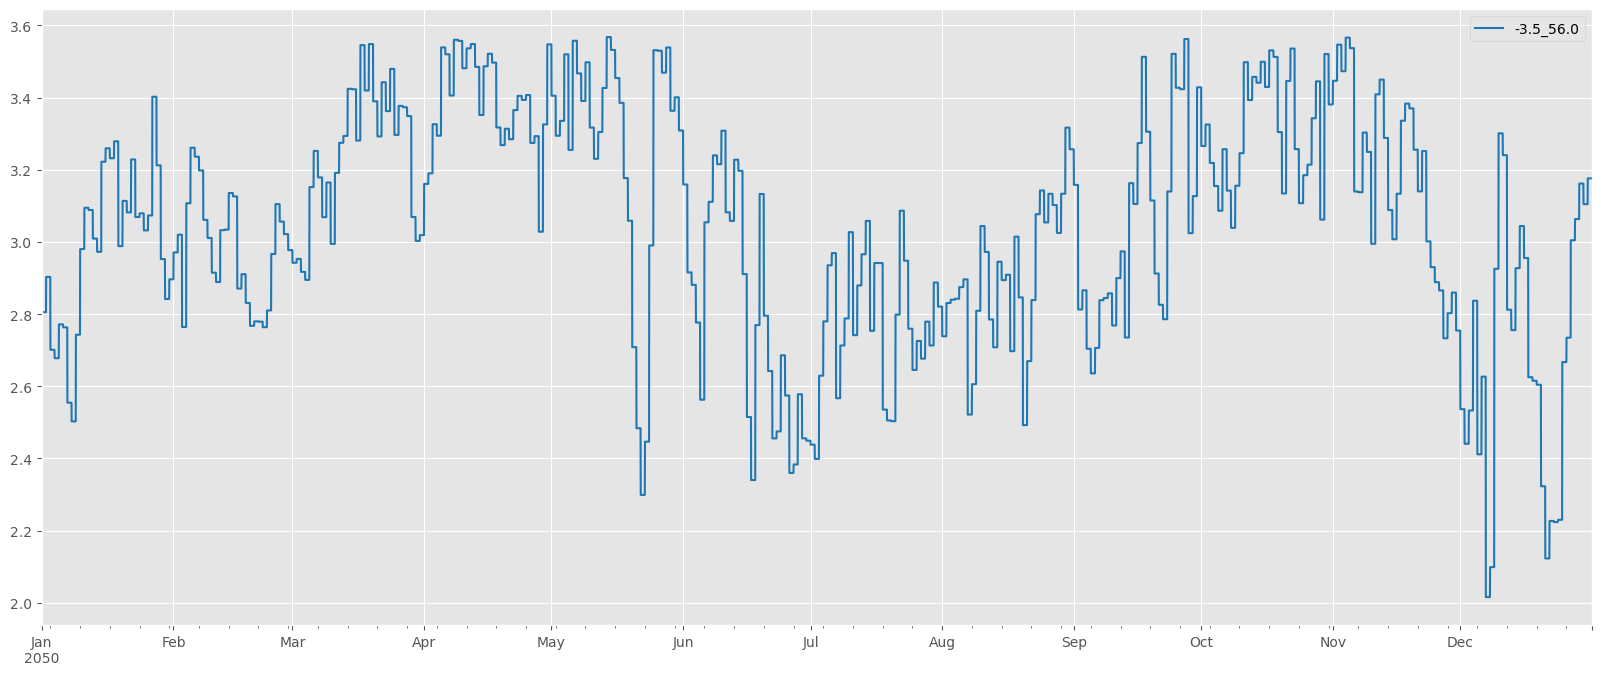

In [6]:
df_ASHP = day_cop_for_year_grid_sq(
    'ASHP',
    'very good',
    future_year=future_year,
    weather_year=weather_year)
df_ASHP_grid_id = df_ASHP[[grid_id]]

plt.style.use('ggplot')
df_ASHP_grid_id.plot(figsize=(20,8), cmap='tab20')

<Axes: >

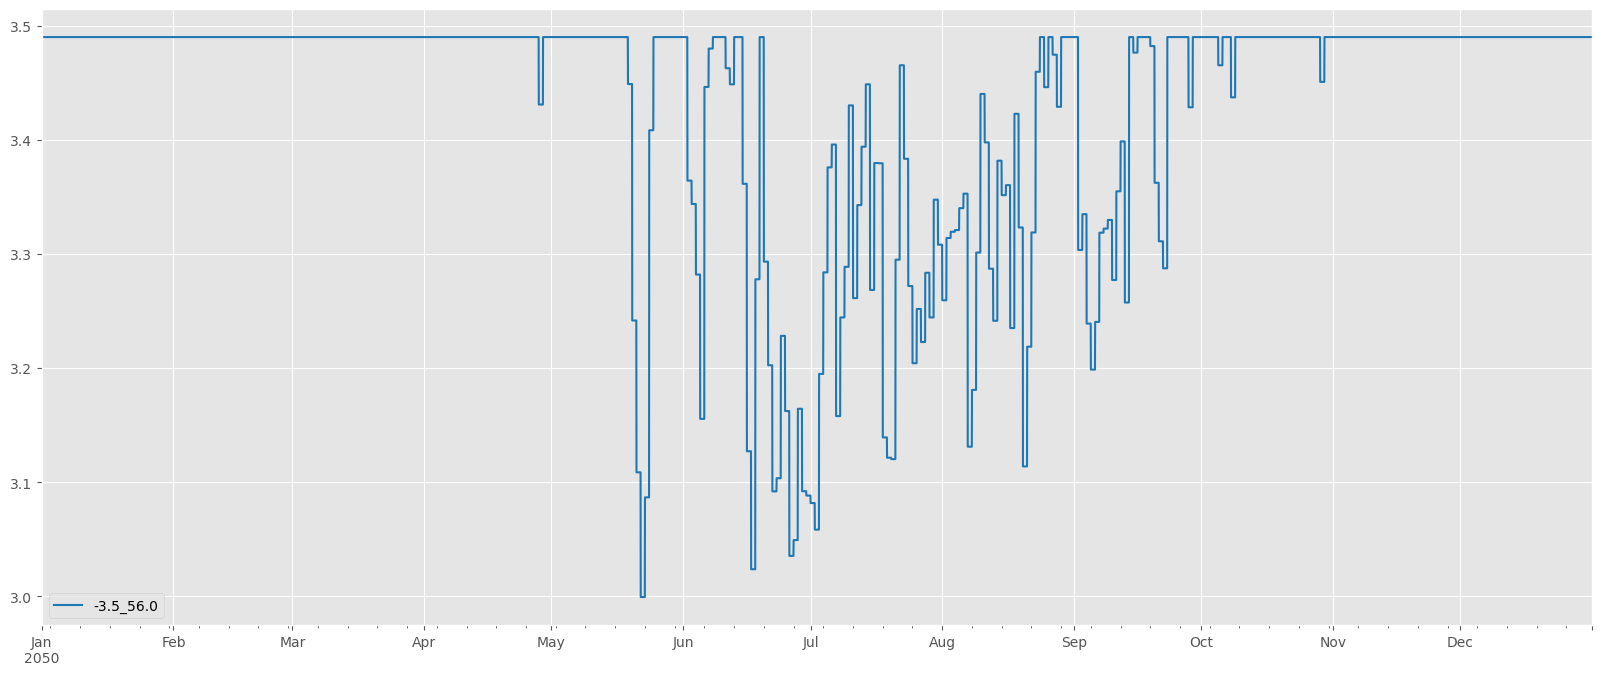

In [7]:
df_GSHP = day_cop_for_year_grid_sq(
    'GSHP',
    'very good',
    future_year=future_year,
    weather_year=weather_year)
df_GSHP_grid_id = df_GSHP[[grid_id]]

plt.style.use('ggplot')
df_GSHP_grid_id.plot(figsize=(20,8), cmap='tab20')

In [8]:
# Run the pipeline (fast if profiles already exist)
profiles = run_heat_profiles_only(
    weather_year=weather_year,
    future_year=future_year,
    FES_year=FES_year,
    scenario=FES_scenario,
)
profiles

✅ All heating profiles already exist. Loading from disk.


{'-0.25_50.75':                              ASHP          GSHP  Gas boiler  Electric storage  \
 2050-01-01 00:00:00  11258.656639  15142.824977    0.022245       4376.303568   
 2050-01-01 00:30:00  11432.756879  15437.775982    0.022006       4486.229197   
 2050-01-01 01:00:00  11802.194533  15943.044839    0.022637       4635.323729   
 2050-01-01 01:30:00  12099.466932  16334.350117    0.023235       4743.733143   
 2050-01-01 02:00:00  12677.736886  17028.991398    0.025089       4909.253344   
 ...                           ...           ...         ...               ...   
 2050-12-31 21:30:00  14402.341976  17189.354432    0.051773       4122.869771   
 2050-12-31 22:00:00  12691.523364  15534.608607    0.041675       3898.181379   
 2050-12-31 22:30:00  11018.155385  13926.605301    0.031541       3683.023992   
 2050-12-31 23:00:00   9766.808681  12727.154130    0.023863       3523.024767   
 2050-12-31 23:30:00   9140.282869  12152.912254    0.019718       3460.363473   
 

In [12]:
# Example grid ID, replace with actual grid ID as needed
# Define the filename
file_name = f"half_hourly_heat_profile_{grid_id}_{weather_year}_{FES_year}_{FES_scenario}_{future_year}.csv"

# Build the folder path inside the data directory
folder = path_in_data(
    "outputs",
    "heating_profiles",
    f"{weather_year}_{FES_year}_{FES_scenario}_{future_year}",
)
# Ensure folder exists
ensure_dir(folder)
# Full file path
file_path = os.path.join(folder, file_name)
# Read the file
hd_df = pd.read_csv(file_path, index_col=0)
# Convert index to datetime
hd_df.index = pd.to_datetime(hd_df.index)
print("Loaded:", file_path)
hd_df.head()

Loaded: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\heating_profiles\2010_2022_LW_2050\half_hourly_heat_profile_-3.5_56.0_2010_2022_LW_2050.csv


,ASHP,GSHP,Gas boiler,Electric storage,Hybrid (ASHP + Electric resistive),Oil boiler,Biomass boiler,BioLPG boiler,Community,Hybrid (ASHP + BioLPG boiler),Hybrid (ASHP + Hydrogen boiler),DH,Electric resistive,Hydrogen boiler
2050-01-01 00:00:00,14572.003622,20095.181659,0.0,7522.509383,6293.958894,0.0,426.727017,979.533684,3.777694,305.253028,92.408440,6521.248448,0.0,113.091420
2050-01-01 00:30:00,14813.632978,20459.600088,0.0,7678.610948,6365.641121,0.0,431.587033,990.689644,3.820719,308.729570,93.460885,6595.519287,0.0,114.379424
2050-01-01 01:00:00,15238.268005,21024.734244,0.0,7883.129042,6627.286658,0.0,449.326459,1031.409741,3.977761,321.419213,97.302387,6866.613455,0.0,119.080736
2050-01-01 01:30:00,15529.387696,21417.319332,0.0,8024.622172,6763.590267,0.0,458.567770,1052.622777,4.059572,328.029852,99.303608,7007.839307,0.0,121.529874
2050-01-01 02:00:00,16055.041005,22038.288369,0.0,8199.506011,7176.813019,0.0,486.584050,1116.932953,4.307592,348.070895,105.370579,7435.984497,0.0,128.954763


<Axes: >

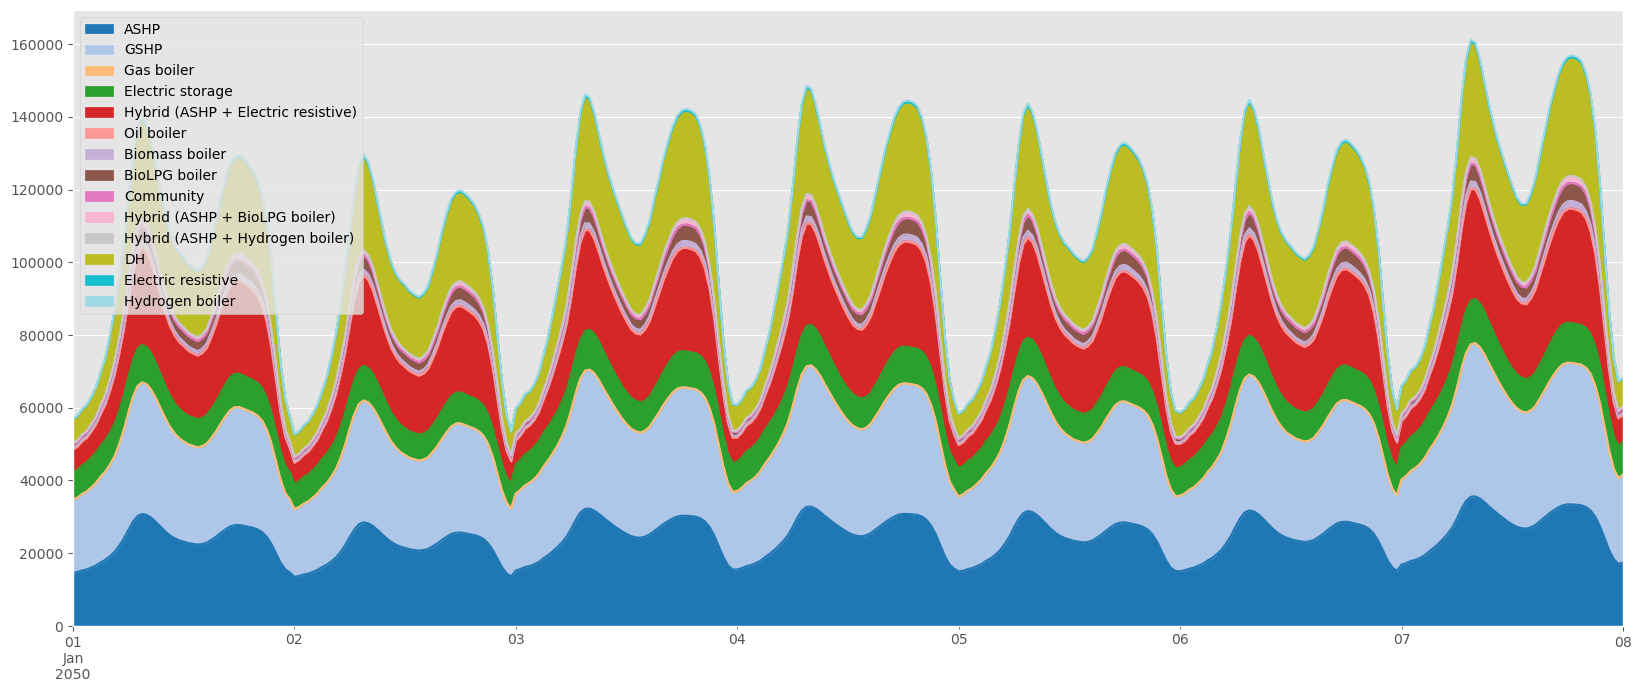

In [13]:
hd_df['2050-01-01 00:00:00': '2050-01-08 00:00:00'].plot.area(figsize=(20,8), cmap='tab20')

In [15]:
profiles['-3.5_56.0']



,ASHP,GSHP,Gas boiler,Electric storage,Hybrid (ASHP + Electric resistive),Oil boiler,Biomass boiler,BioLPG boiler,Community,Hybrid (ASHP + BioLPG boiler),Hybrid (ASHP + Hydrogen boiler),DH,Electric resistive,Hydrogen boiler
2050-01-01 00:00:00,14572.003622,20095.181659,0.0,7522.509383,6293.958894,0.0,426.727017,979.533684,3.777694,305.253028,92.408440,6521.248448,0.0,113.091420
2050-01-01 00:30:00,14813.632978,20459.600088,0.0,7678.610948,6365.641121,0.0,431.587033,990.689644,3.820719,308.729570,93.460885,6595.519287,0.0,114.379424
2050-01-01 01:00:00,15238.268005,21024.734244,0.0,7883.129042,6627.286658,0.0,449.326459,1031.409741,3.977761,321.419213,97.302387,6866.613455,0.0,119.080736
2050-01-01 01:30:00,15529.387696,21417.319332,0.0,8024.622172,6763.590267,0.0,458.567770,1052.622777,4.059572,328.029852,99.303608,7007.839307,0.0,121.529874
2050-01-01 02:00:00,16055.041005,22038.288369,0.0,8199.506011,7176.813019,0.0,486.584050,1116.932953,4.307592,348.070895,105.370579,7435.984497,0.0,128.954763
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2050-12-31 21:30:00,16179.611737,19787.542423,0.0,6145.843632,12840.175809,0.0,870.556991,1998.326478,7.706796,622.740410,188.520554,13303.864542,0.0,230.715475
2050-12-31 22:00:00,14253.908861,17898.347879,0.0,5824.431525,10259.404275,0.0,695.582074,1596.679011,6.157793,497.574622,150.629447,10629.895322,0.0,184.343530
2050-12-31 22:30:00,12344.119110,16019.085463,0.0,5497.917639,7686.044708,0.0,521.109684,1196.185074,4.613238,372.768310,112.847162,7963.605731,0.0,138.104765
2050-12-31 23:00:00,10906.835149,14597.928896,0.0,5245.529608,5758.713309,0.0,390.437655,896.233000,3.456435,279.293955,84.549919,5966.673895,0.0,103.473994


C:\Users\s2583817\AppData\Local\Temp\ipykernel_2712\600186327.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  elec_hd_df['ASHP Elec'] = elec_hd_df['ASHP'] / df_ASHP_grid_id[grid_id]
C:\Users\s2583817\AppData\Local\Temp\ipykernel_2712\600186327.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  elec_hd_df['GSHP Elec'] = elec_hd_df['GSHP'] / df_GSHP_grid_id[grid_id]
C:\Users\s2583817\AppData\Local\Temp\ipykernel_2712\600186327.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a s

<Axes: >

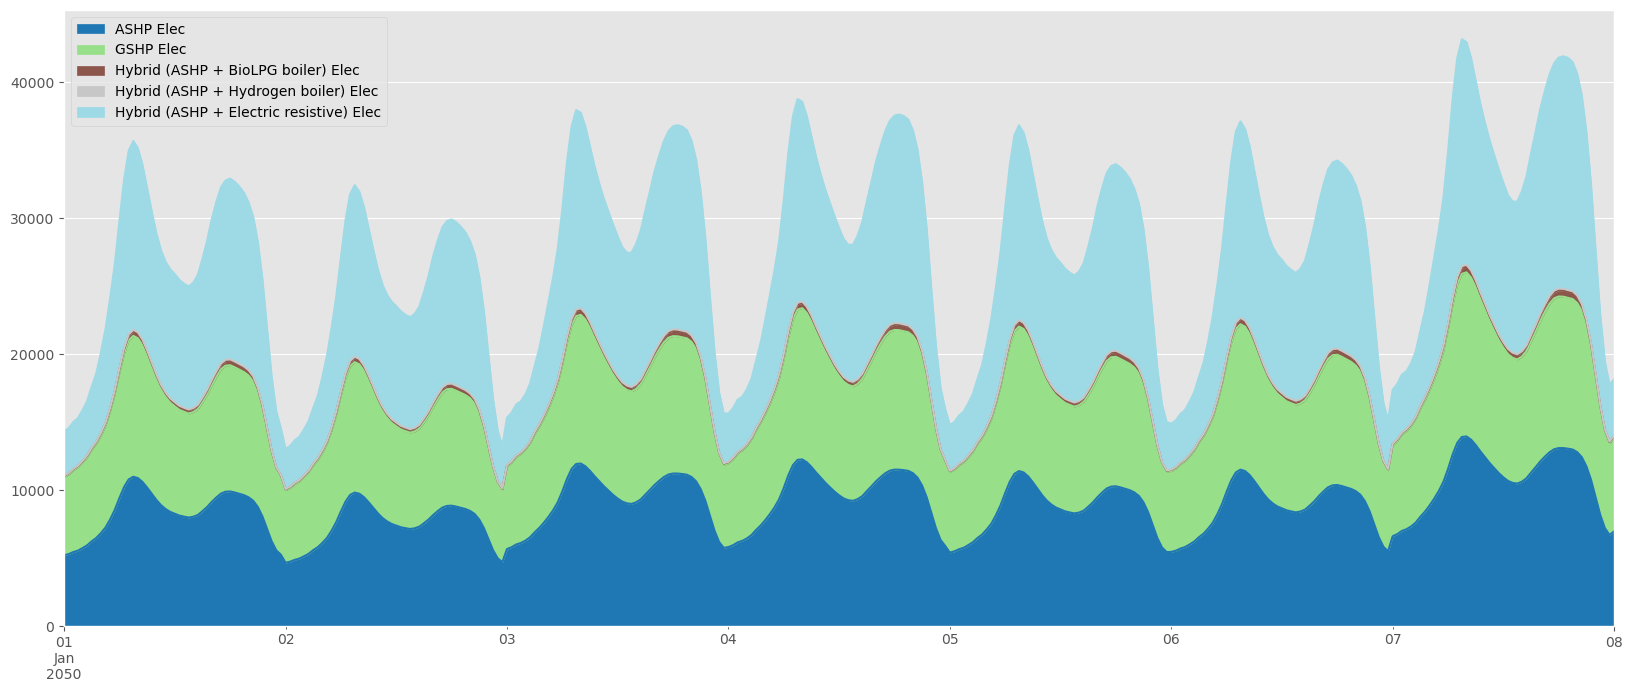

In [16]:
# Select relevant columns
elec_hd_df = hd_df[[
    'ASHP', 'GSHP',
    'Hybrid (ASHP + BioLPG boiler)',
    'Hybrid (ASHP + Hydrogen boiler)',
    'Hybrid (ASHP + Electric resistive)'
]]

# Align all operations by index instead of using .values
elec_hd_df['ASHP Elec'] = elec_hd_df['ASHP'] / df_ASHP_grid_id[grid_id]
elec_hd_df['GSHP Elec'] = elec_hd_df['GSHP'] / df_GSHP_grid_id[grid_id]

elec_hd_df['Hybrid (ASHP + BioLPG boiler) Elec'] = (
    0.75 * elec_hd_df['Hybrid (ASHP + BioLPG boiler)'] / df_ASHP_grid_id[grid_id]
)

elec_hd_df['Hybrid (ASHP + Hydrogen boiler) Elec'] = (
    0.75 * elec_hd_df['Hybrid (ASHP + Hydrogen boiler)'] / df_ASHP_grid_id[grid_id]
)

elec_hd_df['Hybrid (ASHP + Electric resistive) Elec'] = (
    0.75 * elec_hd_df['Hybrid (ASHP + Electric resistive)'] / df_ASHP_grid_id[grid_id]
    + 0.25 * elec_hd_df['Hybrid (ASHP + Electric resistive)']
)

# Plot
elec_hd_df.loc['2050-01-01 00:00:00':'2050-01-08 00:00:00', [
    'ASHP Elec', 'GSHP Elec',
    'Hybrid (ASHP + BioLPG boiler) Elec',
    'Hybrid (ASHP + Hydrogen boiler) Elec',
    'Hybrid (ASHP + Electric resistive) Elec'
]].plot.area(figsize=(20, 8), cmap='tab20')


<Axes: >

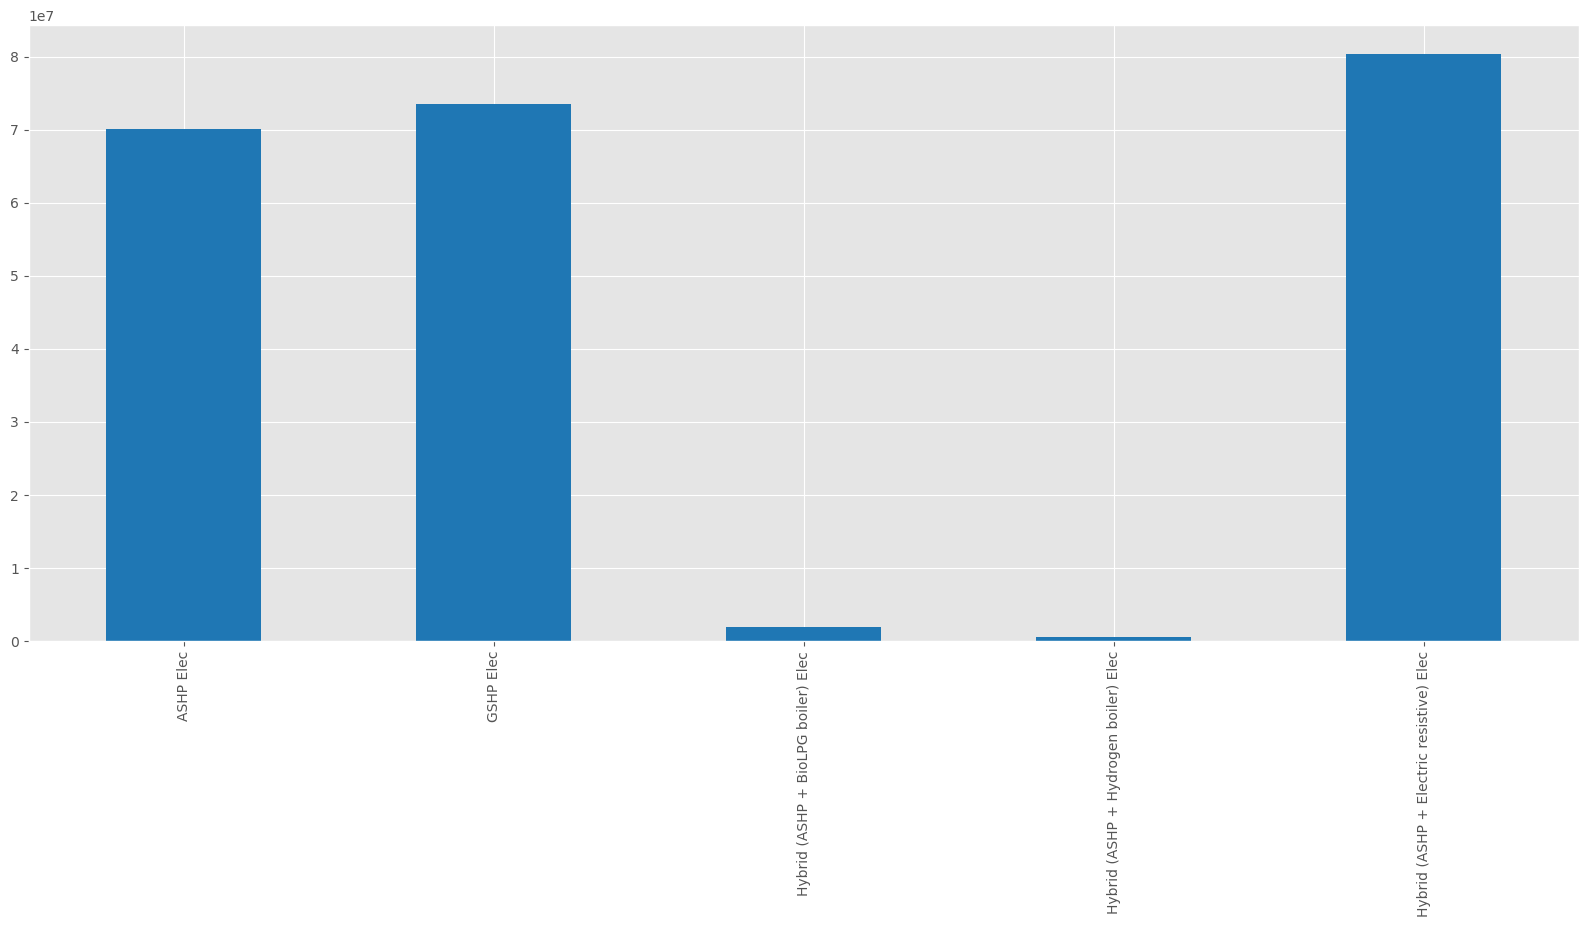

In [17]:
ed_df = elec_hd_df[['ASHP Elec', 'GSHP Elec', 'Hybrid (ASHP + BioLPG boiler) Elec', 'Hybrid (ASHP + Hydrogen boiler) Elec', 'Hybrid (ASHP + Electric resistive) Elec']]
ed_df.sum().plot.bar(figsize=(20,8), cmap='tab20')

In [18]:
# total in GWh
ed_df.sum().sum() / 1000000

226.45268491982037